In [1]:
# ===========================================================================
# CONFIG LOADER  --  edit config.py, NOT this cell.
# Gives you `cfg` (every country knob) and `P` (the standard paths).
# ===========================================================================
import os, sys, importlib.util

# config.py lives in activity/, beside this notebook.
# From activity/ that is simply the current folder; from sols/ it is next door.
CODE_DIR = os.getcwd()
if not os.path.exists(os.path.join(CODE_DIR, "config.py")):
    CODE_DIR = os.path.abspath(os.path.join(CODE_DIR, "..", "activity"))

_spec = importlib.util.spec_from_file_location("config", os.path.join(CODE_DIR, "config.py"))
cfg = importlib.util.module_from_spec(_spec)
_spec.loader.exec_module(cfg)
P = cfg.derive_paths(CODE_DIR)     # creates raw/, data/, output/, logs/ if missing

print(f"[CONFIG] {cfg.COUNTRY} ({cfg.CODE}) | reading output/{cfg.DATE_STR}/")


[CONFIG] Trinidad and Tobago (TT) | reading output/20261020/


# Results

Estimation results are stored in 3 files: the point estimates, the performance (RMSE), and out-of-sample estimates

In [2]:
import numpy as np
import pandas as pd
import os

# DATE_STR comes from config.py, the same value act11_nwcst stamped its output with,
# so these two notebooks cannot drift. To review an older run, pin DATE_STR there.
date_str    = cfg.DATE_STR
PATH_DATA   = P["data"]
PATH_OUTPUT = os.path.join(P["output"], date_str)

forecast_file     = f"{date_str} 3_nwcst Tab fcst.xlsx"   # model forecasts / nowcasts
performance_file  = f"{date_str} 3_nwcst Tab perf.xlsx"   # model performance metrics
outofsample_file  = f"{date_str} 3_nwcst Tab oos.xlsx"    # full OOS prediction panel


results_table = pd.read_excel(f"{PATH_OUTPUT}/{forecast_file}", index_col='date')
results_table.index = pd.to_datetime(results_table.index, format="%Y-%m-%d")
performance_table = pd.read_excel(f"{PATH_OUTPUT}/{performance_file}", index_col='Vintage')
#outofsample_table = pd.read_excel(f"{PATH_OUTPUT}/{outofsample_file}", index_col='date')


**Inspect the performance table.** This shows each model's prediction error (RMSE) broken down by forecasting horizon ("Vintage"): negative numbers mean the data was already published when the model ran; positive means it was predicting quarters that had not been released yet.

In [3]:
performance_table

,RMSE,estimator,spec
Vintage,,,
-2,289.944620,OLS,bench5p3
-1,2.148984,OLS,bench5p3
0,35.383856,OLS,bench5p3
1,292.267286,OLS,bench5p3
2,3.054418,OLS,bench5p3
...,...,...,...
-2,2.884072,GBT,lars67p3
-1,2.937700,GBT,lars67p3
0,3.046985,GBT,lars67p3


**Check which model specifications are present** in the performance data.

In [4]:
performance_table['spec'].unique()

array(['bench5p3', 'lars68p3', 'lars67p3'], dtype=object)

**Inspect the results table.** This contains the actual nowcast values produced by each model, for each quarter and each forecasting horizon.

In [5]:
results_table

,actuals,two_back,one_back,zero_back,one_ahead,two_ahead,estimator,spec
date,,,,,,,,
2023-06-01,1.543951,-12.096071,0.590578,-0.338526,-0.973085,-2.405205,OLS,bench5p3
2023-09-01,-2.226164,-0.885312,-1.554275,-0.216340,2.239026,-0.416237,OLS,bench5p3
2023-12-01,-0.783313,2.147469,-0.478114,-0.793251,2.169699,1.881862,OLS,bench5p3
2024-03-01,2.520533,1.846870,1.563193,-2.352660,-17.043331,1.781989,OLS,bench5p3
2024-06-01,-1.226503,-25.915962,1.828047,-1.343843,-20.009805,-0.212181,OLS,bench5p3
...,...,...,...,...,...,...,...,...
2025-03-01,-3.079058,0.143371,-0.209765,-0.801320,-0.397025,0.388978,GBT,lars67p3
2025-06-01,4.631900,-0.812836,-0.733338,0.017405,0.152387,-0.718468,GBT,lars67p3
2025-09-01,-0.899062,0.263081,1.402445,0.041415,0.184779,1.068887,GBT,lars67p3


**Check which model specifications are present** in the results data.

In [6]:
results_table['spec'].unique()

array(['bench5p3', 'lars68p3', 'lars67p3'], dtype=object)

# Presenting Results

**Set up plotting libraries and color palette.** We import the tools needed to draw charts and define the IDB color scheme used throughout.

In [7]:
import matplotlib.ticker as ticker
import matplotlib.pyplot as plt
import seaborn as sns

# Define the color scheme
idb_blue = "#005BAC"
idb_light_blue = "#7FB3E6"

## Average RMSE by publication lag

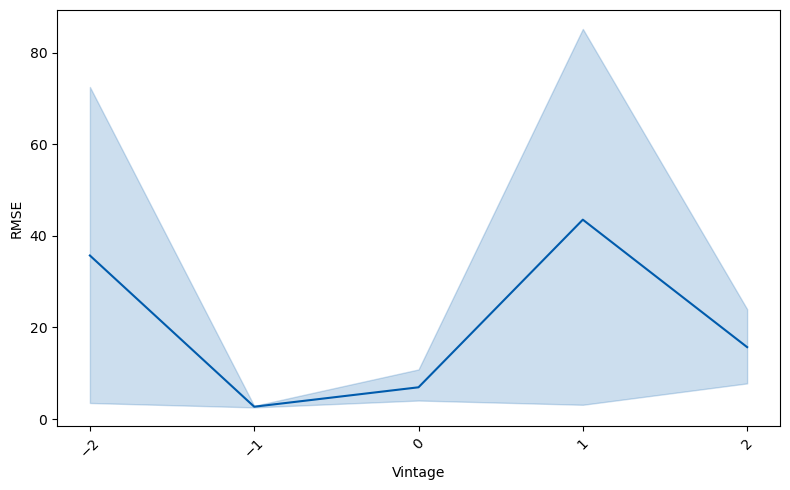

In [8]:
all_means = performance_table.groupby(performance_table.index)['RMSE'].mean()


fig, axes = plt.subplots(1, 1, figsize=(8, 5))  # adjust figsize as you want
# If axes is a single AxesSubplot (not an array), make it a list for consistency
axes = [axes]

# Plot
sns.lineplot(data=performance_table, x='Vintage', y='RMSE', ax=axes[0], color=idb_blue)

axes[0].xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
axes[0].set_title("")
axes[0].tick_params(axis='x', rotation=45)
plt.tight_layout()

# Save figure:
plt.savefig(f'{PATH_OUTPUT}/Figure Vintage.png')
plt.show()

## Boxplot by publication lag

C:\Users\guerr\anaconda3\envs\nwcst\Lib\site-packages\seaborn\categorical.py:700: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  artists = ax.bxp(**boxplot_kws)


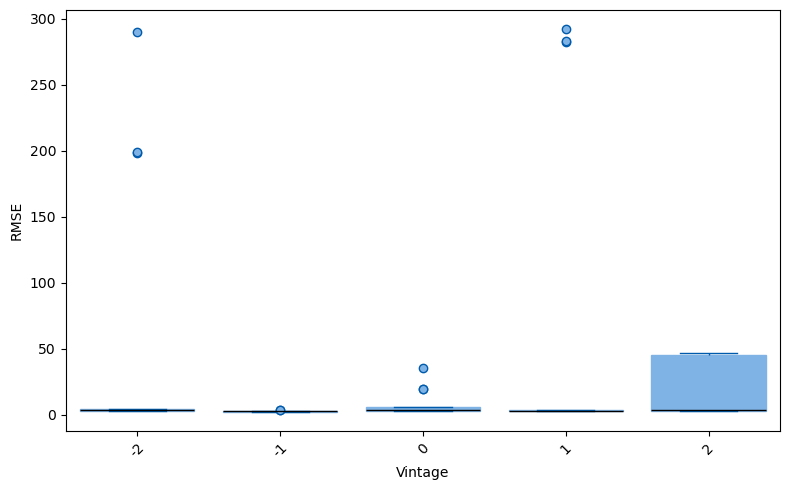

In [9]:
df = performance_table.reset_index()

fig, ax = plt.subplots(figsize=(8, 5))

# If you want a specific order, define it here; otherwise seaborn will infer it.
# order = sorted(df['Publication lag'].unique())
order = None

sns.boxplot(
    data=df,
    x='Vintage',
    y='RMSE',
    order=order,
    ax=ax,
    boxprops=dict(color=idb_light_blue),
    whiskerprops=dict(color=idb_blue),
    capprops=dict(color=idb_blue),
    medianprops=dict(color='black'),
    flierprops=dict(markerfacecolor=idb_light_blue, markeredgecolor=idb_blue,
                    marker='o', markersize=6)
)

ax.set_title("")
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

**Same boxplot with mean markers added.** The dot in each box shows the average RMSE for that publication lag, making it easier to compare central tendency across vintages.

C:\Users\guerr\anaconda3\envs\nwcst\Lib\site-packages\seaborn\categorical.py:700: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  artists = ax.bxp(**boxplot_kws)


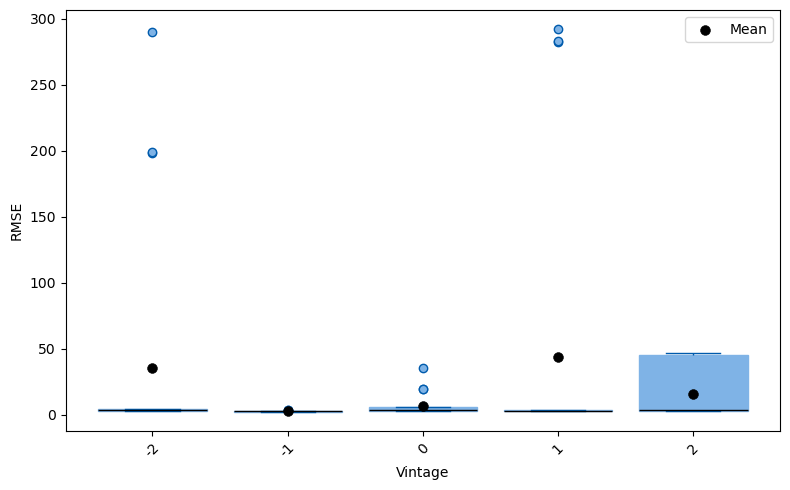

In [10]:
df = performance_table.reset_index()

fig, ax = plt.subplots(figsize=(8, 5))

# If you want a specific order, define it here; otherwise seaborn will infer it.
# order = sorted(df['Publication lag'].unique())
order = None

sns.boxplot(
    data=df,
    x='Vintage',
    y='RMSE',
    order=order,
    ax=ax,
    boxprops=dict(color=idb_light_blue),
    whiskerprops=dict(color=idb_blue),
    capprops=dict(color=idb_blue),
    medianprops=dict(color='black'),
    flierprops=dict(markerfacecolor=idb_light_blue, markeredgecolor=idb_blue,
                    marker='o', markersize=6)
)

# Get the actual category order used on the axis (this is key)
cats = [t.get_text() for t in ax.get_xticklabels()]

# Means computed in the same category space as the plot
means = df.groupby('Vintage', dropna=False)['RMSE'].mean()

# Map tick labels -> x positions
xpos = np.arange(len(cats))

# Overlay means (match tick labels carefully)
ymeans = []
for c in cats:
    # Try direct label
    if c in means.index:
        ymeans.append(means.loc[c])
        continue
    # Try numeric label -> numeric index match (common when lag is int/float)
    try:
        cnum = float(c)
        hit = None
        for idx in means.index:
            try:
                if float(idx) == cnum:
                    hit = means.loc[idx]
                    break
            except Exception:
                pass
        ymeans.append(hit)
    except Exception:
        ymeans.append(None)

# Plot only the ones we found
mask = [v is not None and np.isfinite(v) for v in ymeans]
ax.scatter(
    xpos[mask],
    np.array(ymeans, dtype=float)[mask],
    color='black',
    marker='o',
    s=50,
    zorder=10,
    edgecolor='k',
    linewidth=0.4,
    label='Mean'
)

# Clean legend (only "Mean" once)
handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
ax.legend(by_label.values(), by_label.keys())

ax.set_title("")
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

## Histogram: distribution of errors

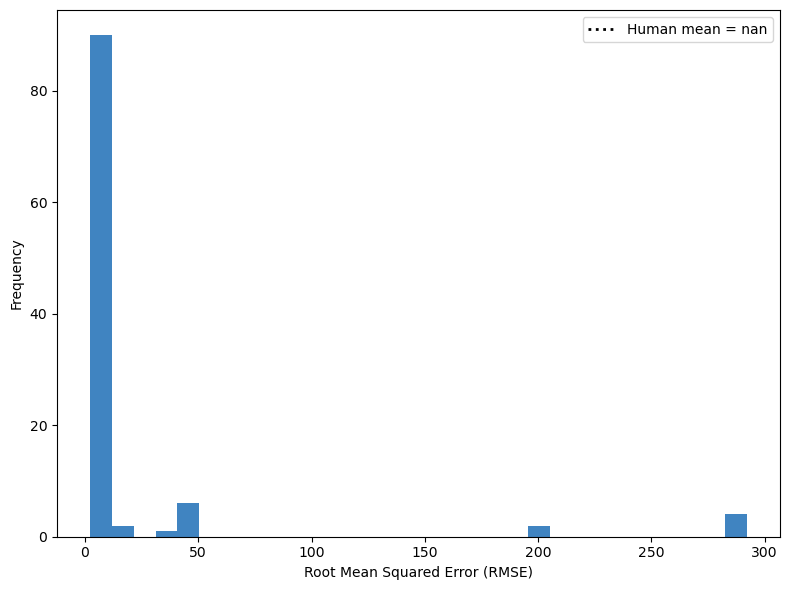

In [11]:
human_mean = performance_table[performance_table['spec']=='human1']['RMSE'].mean()

plt.figure(figsize=(8, 6))

# Plot with Seaborn, no edge lines
sns.histplot(performance_table['RMSE'], bins=30, kde=False, color=idb_blue, edgecolor=None)

# Median line
plt.axvline(human_mean, color='black', linestyle=':', linewidth=2, label=f'Human mean = {human_mean:.2f}')

plt.title("")
plt.xlabel("Root Mean Squared Error (RMSE)")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()

**Filter out extreme outliers using the vintage mean**

In [12]:
spec_rmse_mean = pd.DataFrame(performance_table.groupby('Vintage')['RMSE'].median())
spec_rmse_mean = spec_rmse_mean.rename(columns={'RMSE': 'threshold'})
spec_rmse_mean

,threshold
Vintage,
-2,3.565839
-1,2.672859
0,3.935588
1,3.047750
2,3.463564


**Apply the outlier filter and redraw the histogram.** Models whose RMSE exceeds the vintage-specific median are dropped. The histogram now shows the cleaned error distribution alongside the human-forecaster benchmark.

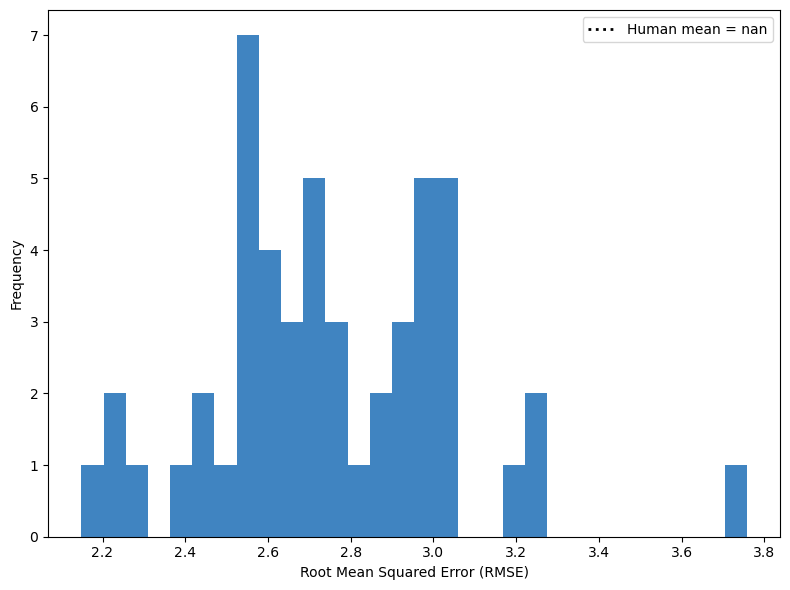

In [13]:
performance_table = performance_table.merge(spec_rmse_mean, on='Vintage', how='left')

# ++++++++++++++++++++++++++++++++++++++++++++++++++++
# ++++++++++++++++++++++++++++++++++++++++++++++++++++
filtered = performance_table[performance_table['RMSE'] < performance_table['threshold']]
# ++++++++++++++++++++++++++++++++++++++++++++++++++++
# ++++++++++++++++++++++++++++++++++++++++++++++++++++


human_mean = performance_table[performance_table['spec']=='human1']['RMSE'].mean()

plt.figure(figsize=(8, 6))

# Plot with Seaborn, no edge lines
sns.histplot(filtered['RMSE'], bins=30, kde=False, color=idb_blue, edgecolor=None)

# Median line
plt.axvline(human_mean, color='black', linestyle=':', linewidth=2, label=f'Human mean = {human_mean:.2f}')

plt.title("")
plt.xlabel("Root Mean Squared Error (RMSE)")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()

## Histogram conditional on publication lag

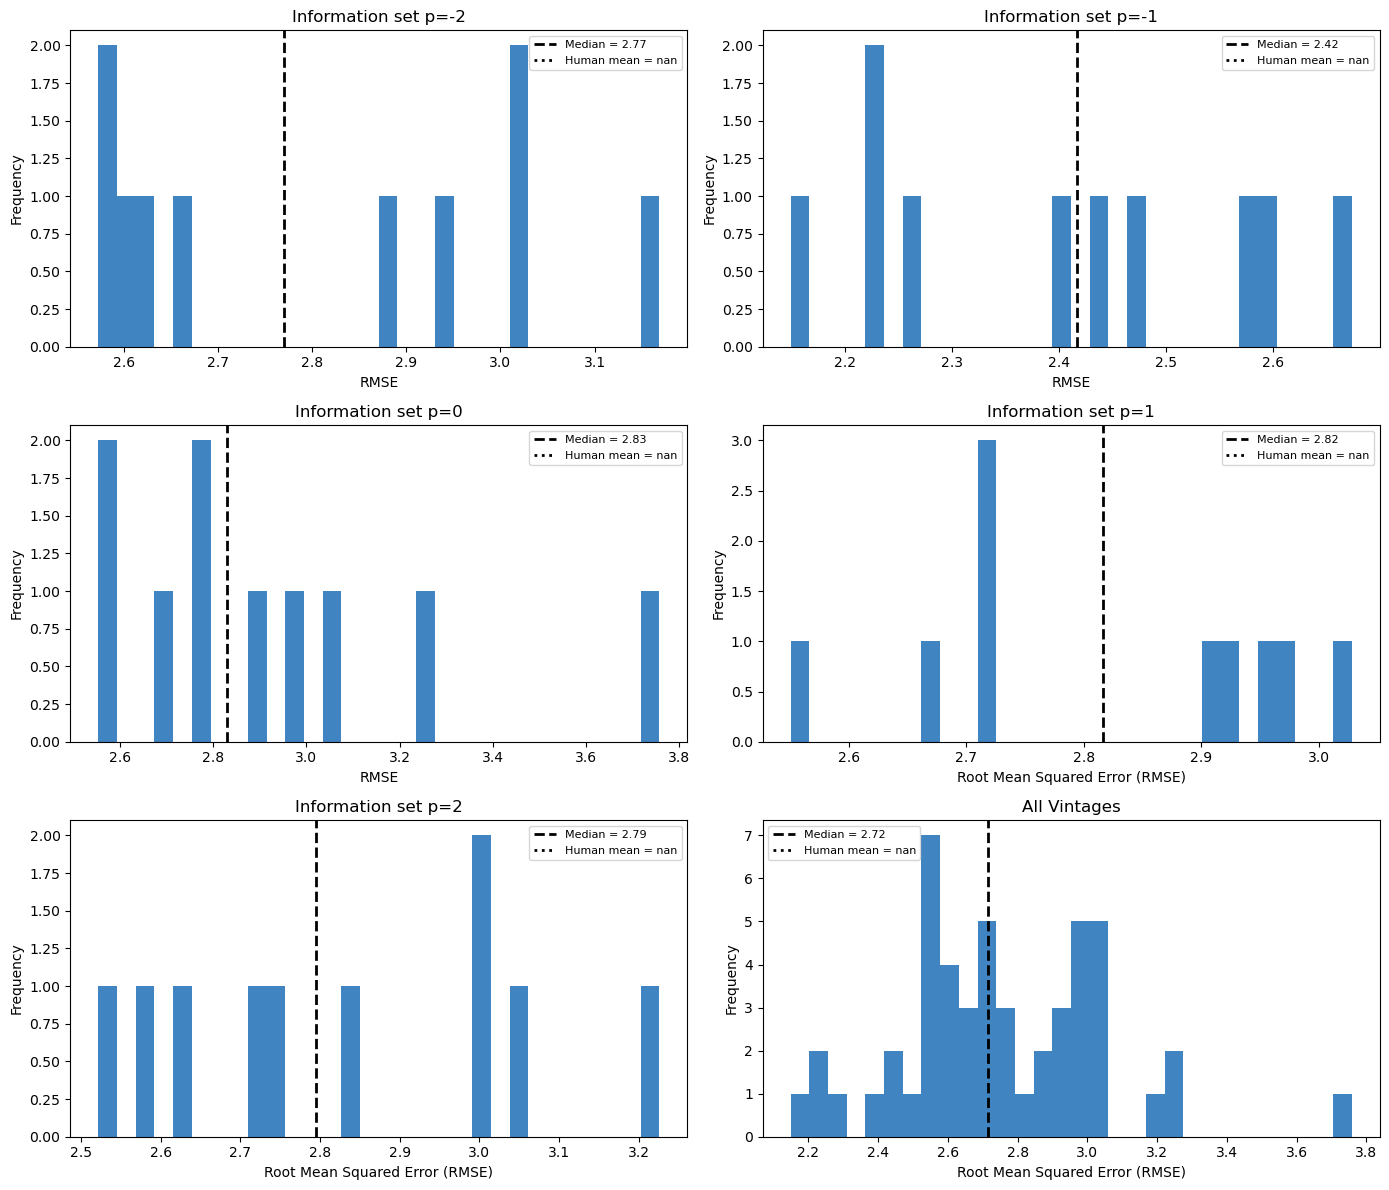

In [14]:
human_means = (
    performance_table[performance_table['spec'] == 'human1']
    .groupby('Vintage')
    .mean(numeric_only=True)
)

# Mapping of vintages
lags = {
    -2: 'two_back',
    -1: 'one_back',
     0: 'zero_back',
     1: 'one_ahead',
     2: 'two_ahead'
}

fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(14, 12), sharex=False, sharey=False)
axes = axes.flatten()

# ------------------------------------------------
# Loop over each vintage and plot histogram
for i, (V, N) in enumerate(lags.items()):
    ax = axes[i]

    # Filter data for this vintage
    subset = filtered[filtered.index == V]

    # Histogram
    sns.histplot(subset['RMSE'], bins=30, kde=False, color=idb_blue, edgecolor=None, ax=ax)

    # Median line
    rmse_median = subset['RMSE'].median()
    ax.axvline(rmse_median, color='black', linestyle='dashed', linewidth=2, label=f'Median = {rmse_median:.2f}')

    # Human benchmark
    human_mean = human_means[human_means.index==V]['RMSE'].mean()
    ax.axvline(human_mean, color='black', linestyle=':', linewidth=2, label=f'Human mean = {human_mean:.2f}')

    # Titles
    ax.set_title(f'Information set p={V}', fontsize=12)
    ax.set_ylabel('Frequency')
    ax.legend(fontsize=8, loc='upper right')

# ------------------------------------------------
# Last panel: pooled distribution
ax = axes[-1]
sns.histplot(filtered['RMSE'], bins=30, kde=False, color=idb_blue, edgecolor=None, ax=ax)

rmse_median = filtered['RMSE'].median()
ax.axvline(rmse_median, color='black', linestyle='dashed', linewidth=2, label=f'Median = {rmse_median:.2f}')

human_mean = performance_table[performance_table['spec'] == 'human1']['RMSE'].mean()
ax.axvline(human_mean, color='black', linestyle=':', linewidth=2, label=f'Human mean = {human_mean:.2f}')

ax.set_title('All Vintages', fontsize=12)
ax.set_ylabel('Frequency')
ax.legend(fontsize=8, loc='upper left')

# ------------------------------------------------
# X-labels on bottom row
for ax in axes[-3:]:
    ax.set_xlabel("Root Mean Squared Error (RMSE)")

plt.tight_layout()
plt.show()

## Boxplot (outliers management)

C:\Users\guerr\anaconda3\envs\nwcst\Lib\site-packages\seaborn\categorical.py:700: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  artists = ax.bxp(**boxplot_kws)


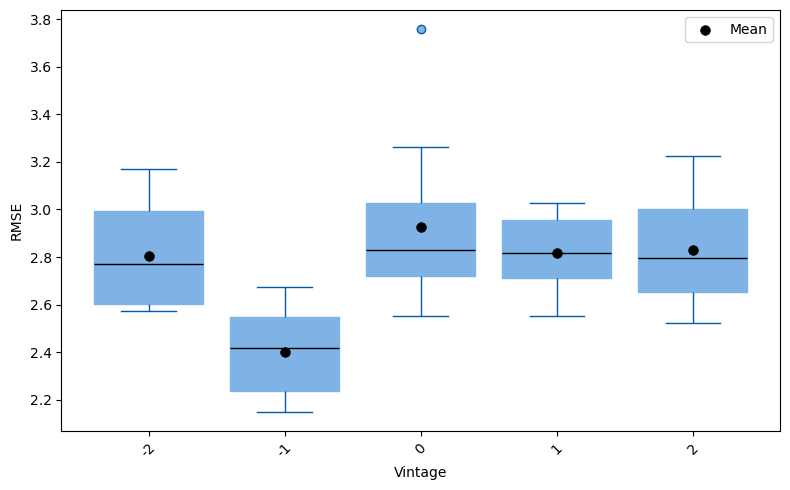

In [15]:
# First we define reference points
human_p = performance_table[performance_table['spec']=='human1']
human_p = human_p.groupby(human_p.index)['RMSE'].mean()
all_means = filtered.groupby(filtered.index)['RMSE'].mean()


fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(
    data=filtered.reset_index(),
    x='Vintage',
    y='RMSE',
    ax=ax,
    boxprops=dict(color=idb_light_blue),
    whiskerprops=dict(color=idb_blue),
    capprops=dict(color=idb_blue),
    medianprops=dict(color='black'),
    flierprops=dict(markerfacecolor=idb_light_blue, markeredgecolor=idb_blue, marker='o', markersize=6)
)

# Ensure the figure is rendered so tick labels are available
fig.canvas.draw()   # <- important

xticks = ax.get_xticks()
xtlabels = [t.get_text() for t in ax.get_xticklabels()]

# compute means (keep original dtype)
all_means = filtered.reset_index().groupby('Vintage')['RMSE'].mean()

def find_mean_for_label(lbl):
    # direct match
    if lbl in all_means.index:
        return all_means.loc[lbl]
    # try numeric match
    try:
        lbl_num = float(lbl)
        for idx in all_means.index:
            try:
                if float(idx) == lbl_num:
                    return all_means.loc[idx]
            except Exception:
                continue
    except Exception:
        pass
    # fallback: match by string representation
    for idx in all_means.index:
        if str(idx) == lbl:
            return all_means.loc[idx]
    return None

# plot mean markers aligned to the xtick positions
for i, lbl in enumerate(xtlabels):
    m = find_mean_for_label(lbl)
    if m is not None:
        ax.scatter(xticks[i], m, color='black', marker='o', s=50, zorder=10,
                   label='Mean' if i == 0 else "", edgecolor='k', linewidth=0.4)

# overlay human points: match similarly
for i, vintage in enumerate(human_p.index):
    # try to find which xtick corresponds
    for j, lbl in enumerate(xtlabels):
        try:
            if str(vintage) == lbl or float(vintage) == float(lbl):
                ax.scatter(xticks[j], human_p[vintage], color='black', marker='v', s=50,
                           label='Human' if i == 0 else "")
                break
        except Exception:
            if str(vintage) == lbl:
                ax.scatter(xticks[j], human_p[vintage], color='black', marker='v', s=50,
                           label='Human' if i == 0 else "")
                break

# clean legend
handles, labels = ax.get_legend_handles_labels()
unique = dict(zip(labels, handles))
ax.legend(unique.values(), unique.keys())

ax.set_title("")
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()


# Nowcast outputs:

## Results/RMSE merge

Filter out results from under-performing models

In [16]:
# -----------------------------------------------
# Reshape results to long format
df = results_table.reset_index().melt(
    id_vars=["date", 'spec', 'estimator'],
    value_vars=["two_back", "one_back", "zero_back", "one_ahead", "two_ahead"],
    var_name="horizon",
    value_name="value"
)

# Make Vintage column based on horizon -2, -1, 0, 1, 2
df['Vintage'] = df['horizon'].map({
    'two_back': -2,
    'one_back': -1,
    'zero_back': 0,
    'one_ahead': 1,
    'two_ahead': 2
})
df

,date,spec,estimator,horizon,value,Vintage
0,2023-06-01,bench5p3,OLS,two_back,-12.096071,-2
1,2023-09-01,bench5p3,OLS,two_back,-0.885312,-2
2,2023-12-01,bench5p3,OLS,two_back,2.147469,-2
3,2024-03-01,bench5p3,OLS,two_back,1.846870,-2
4,2024-06-01,bench5p3,OLS,two_back,-25.915962,-2
...,...,...,...,...,...,...
1255,2025-03-01,lars67p3,GBT,two_ahead,0.388978,2
1256,2025-06-01,lars67p3,GBT,two_ahead,-0.718468,2
1257,2025-09-01,lars67p3,GBT,two_ahead,1.068887,2
1258,2025-12-01,lars67p3,GBT,two_ahead,-0.002472,2


**Attach each model's RMSE to its nowcast values.** We join the performance table onto the long-format results so that every prediction row carries the corresponding model error — needed for the quality filter below.

In [17]:
p = performance_table.reset_index()
results_w = (
    df  # safe even if index is unnamed
    .rename(columns=str.strip)
    .merge(
        p.rename(columns=str.strip)[['Vintage','spec','estimator','RMSE']],
        on=['Vintage','spec','estimator'],
        how='left'
    )
)
results_w

,date,spec,estimator,horizon,value,Vintage,RMSE
0,2023-06-01,bench5p3,OLS,two_back,-12.096071,-2,289.944620
1,2023-09-01,bench5p3,OLS,two_back,-0.885312,-2,289.944620
2,2023-12-01,bench5p3,OLS,two_back,2.147469,-2,289.944620
3,2024-03-01,bench5p3,OLS,two_back,1.846870,-2,289.944620
4,2024-06-01,bench5p3,OLS,two_back,-25.915962,-2,289.944620
...,...,...,...,...,...,...,...
1255,2025-03-01,lars67p3,GBT,two_ahead,0.388978,2,3.225836
1256,2025-06-01,lars67p3,GBT,two_ahead,-0.718468,2,3.225836
1257,2025-09-01,lars67p3,GBT,two_ahead,1.068887,2,3.225836
1258,2025-12-01,lars67p3,GBT,two_ahead,-0.002472,2,3.225836


**Keep only the better-performing models.** For each forecasting horizon we discard models whose RMSE is above the horizon average, retaining only those that have predicted well historically.

In [18]:
mean_rmse = results_w.groupby('Vintage')['RMSE'].mean()

# Keep rows with RMSE <= Vintage-specific mean
filtered = results_w[
    results_w['RMSE'] <= results_w['Vintage'].map(mean_rmse)
]
filtered

,date,spec,estimator,horizon,value,Vintage,RMSE
12,2023-06-01,bench5p3,OLSR,two_back,-1.127900,-2,4.090583
13,2023-09-01,bench5p3,OLSR,two_back,-0.079192,-2,4.090583
14,2023-12-01,bench5p3,OLSR,two_back,-0.007256,-2,4.090583
15,2024-03-01,bench5p3,OLSR,two_back,-0.005530,-2,4.090583
16,2024-06-01,bench5p3,OLSR,two_back,-1.767863,-2,4.090583
...,...,...,...,...,...,...,...
1255,2025-03-01,lars67p3,GBT,two_ahead,0.388978,2,3.225836
1256,2025-06-01,lars67p3,GBT,two_ahead,-0.718468,2,3.225836
1257,2025-09-01,lars67p3,GBT,two_ahead,1.068887,2,3.225836
1258,2025-12-01,lars67p3,GBT,two_ahead,-0.002472,2,3.225836


## Ridge plot

In [19]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

df = filtered[['date', 'horizon', 'Vintage', 'value']]
observed = pd.DataFrame(results_table['actuals'].groupby(results_table.index).mean())
actuals_dict = observed['actuals'].to_dict()
df

,date,horizon,Vintage,value
12,2023-06-01,two_back,-2,-1.127900
13,2023-09-01,two_back,-2,-0.079192
14,2023-12-01,two_back,-2,-0.007256
15,2024-03-01,two_back,-2,-0.005530
16,2024-06-01,two_back,-2,-1.767863
...,...,...,...,...
1255,2025-03-01,two_ahead,2,0.388978
1256,2025-06-01,two_ahead,2,-0.718468
1257,2025-09-01,two_ahead,2,1.068887
1258,2025-12-01,two_ahead,2,-0.002472


**Draw the ridge plot.** Each row is one quarter; the colored curves show how the nowcast values are spread across models for each horizon. This reveals how much uncertainty exists at different information sets.

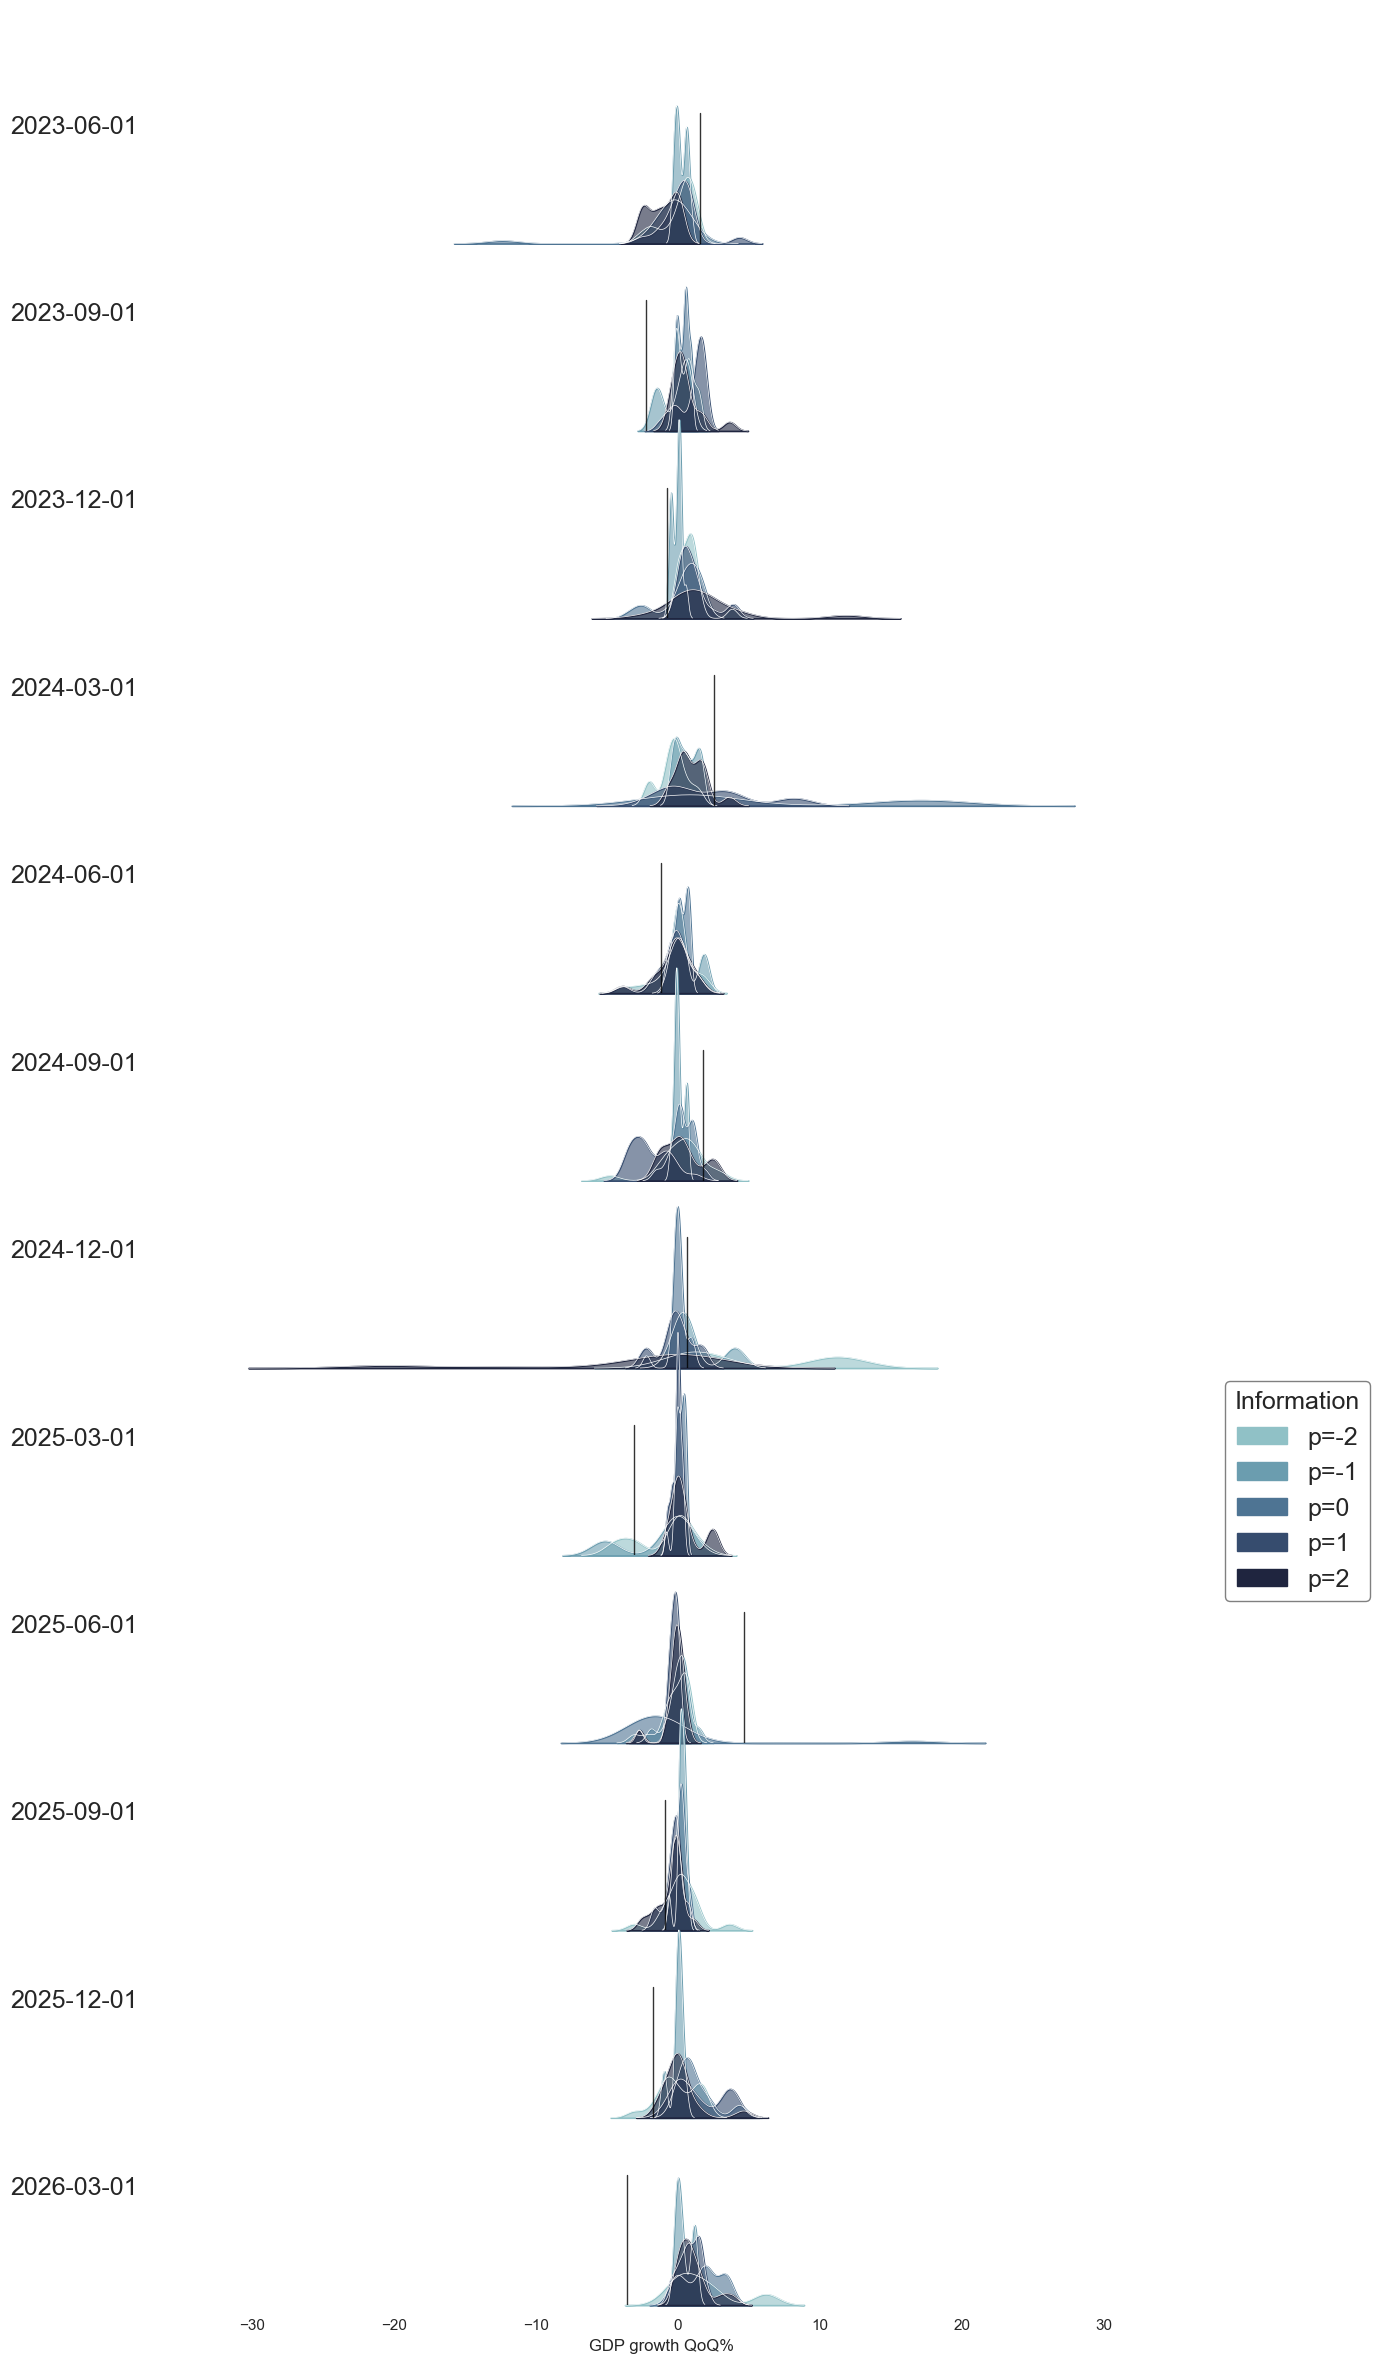

In [20]:
# Mock data to make the code runnable
dates = df["date"].unique()
horizons = ["two_back", "one_back", "zero_back", "one_ahead", "two_ahead"]
data = []
for date in dates:
    for horizon in horizons:
        # Create different distribution shapes to make the plot more interesting
        values = df[(df['date']==date) & (df['horizon']==horizon)].value
        data.extend([(date, horizon, v) for v in values])

df = pd.DataFrame(data, columns=["date", "horizon", "value"])

horizon_labels = {
    "two_back": "p=-2",
    "one_back": "p=-1",
    "zero_back": "p=0",
    "one_ahead": "p=1",
    "two_ahead": "p=2"
}
df["horizon"] = df["horizon"].map(horizon_labels)

sns.set_theme(style="white", rc={"axes.facecolor": (0, 0, 0, 0)})

# Generate a range of colors for the horizons
horizons_unique = df["horizon"].unique()
n_horizons = len(horizons_unique)
pal = sns.cubehelix_palette(n_horizons, rot=-.25, light=.7)

# The fix is to add sharey=False
g = sns.FacetGrid(
    df,  
    row="date",  
    hue="horizon",  
    aspect=5,  
    height=2,  
    palette=pal,
    sharey=True  # This is the key change
)

# KDE distributions
g.map(
    sns.kdeplot,  
    "value",  
    bw_adjust=0.7,  
    clip_on=False,  
    fill=True,  
    alpha=0.6,  
    linewidth=1.2,
    common_norm=True
)

# Contour lines
g.map(
    sns.kdeplot,  
    "value",  
    bw_adjust=0.7,  
    clip_on=False,  
    color="w",  
    lw=0.5
)

# Adjust spacing between ridges
g.fig.subplots_adjust(hspace=-0.2)

# Y-axis labels as dates, remove density scale
for ax, date in zip(g.axes.flat, df["date"].unique()):
    ax.set_ylabel(date.strftime("%Y-%m-%d"), rotation=0, labelpad=50, ha="right", va="center", fontsize=18)
    ax.set_yticks([])
    ax.axhline(y=0, color="gray", lw=0.6, ls="--", alpha=0.7)

# Add observed (example without results_table)
# Loop through the axes and sorted dates to plot the correct 'actual' value
sorted_dates = sorted(df["date"].unique())
for ax, date in zip(g.axes.flat, sorted_dates):
    actual_value = actuals_dict.get(date)
    if actual_value is not None:
        # Create a line with y-coordinates from 0.1 to 0.9 of the axes height,
        # but with the x-coordinate in data units.
        line = plt.Line2D(
            [actual_value, actual_value], # x-coordinates in data units
            [0, 0.9],                   # y-coordinates in axes units
            transform=ax.transData,       # This is the correct transform object
            color='black', linestyle='-', lw=1, alpha=0.8
        )
        # Add the line to the current axes.
        ax.add_line(line)
     
# Cleanup axes
g.set(xlabel="GDP growth QoQ%")
g.set_titles("")
g.despine(bottom=True, left=True)

# Custom white legend
palette_dict = dict(zip(horizons_unique, pal))
handles = [mpatches.Patch(color=palette_dict[h], label=h) for h in horizons_unique]
plt.legend(
    handles=handles,  
    title="Information",  
    title_fontsize=18,  
    fontsize=18,  
    bbox_to_anchor=(1.2, 4),  
    loc="upper center",
    frameon=True,
    facecolor="white",
    edgecolor="gray",
    framealpha=1
)

# Save and show
plt.show()

## Weighted Nowcast

We will weight the nowcast by the inverse of the RMSE. Effectively, we will compute:

$$
\hat{v}
= \frac{\sum_{i=1}^{N} w_i \, v_i}{\sum_{i=1}^{N} w_i}
= \frac{\sum_{i=1}^{N} \dfrac{v_i}{\mathrm{RMSE}_i}}
       {\sum_{i=1}^{N} \dfrac{1}{\mathrm{RMSE}_i}}
$$

We can also estimate a weighted confidence interval using the same weights.

$$
\mathrm{SE}(\hat{v})
= \frac{1}{\sqrt{\sum_{i=1}^{N} w_i}}
= \left( \sum_{i=1}^{N} \frac{1}{\mathrm{RMSE}_i} \right)^{-1/2}
$$

$$
\hat{v} \pm 1.96 \cdot \mathrm{SE}(\hat{v})
$$



In [21]:
filtered = filtered.copy()
filtered['date'] = pd.to_datetime(filtered['date'])
filtered['weight'] = 1 / filtered['RMSE']
filtered

,date,spec,estimator,horizon,value,Vintage,RMSE,weight
12,2023-06-01,bench5p3,OLSR,two_back,-1.127900,-2,4.090583,0.244464
13,2023-09-01,bench5p3,OLSR,two_back,-0.079192,-2,4.090583,0.244464
14,2023-12-01,bench5p3,OLSR,two_back,-0.007256,-2,4.090583,0.244464
15,2024-03-01,bench5p3,OLSR,two_back,-0.005530,-2,4.090583,0.244464
16,2024-06-01,bench5p3,OLSR,two_back,-1.767863,-2,4.090583,0.244464
...,...,...,...,...,...,...,...,...
1255,2025-03-01,lars67p3,GBT,two_ahead,0.388978,2,3.225836,0.309997
1256,2025-06-01,lars67p3,GBT,two_ahead,-0.718468,2,3.225836,0.309997
1257,2025-09-01,lars67p3,GBT,two_ahead,1.068887,2,3.225836,0.309997
1258,2025-12-01,lars67p3,GBT,two_ahead,-0.002472,2,3.225836,0.309997


**Pull out the observed (actual) GDP values.** These are the true outcomes the models were trying to predict — we will compare nowcasts against them in the next steps.

In [22]:
df = results_table[['actuals']]
df = df.groupby('date').mean()
df.index = pd.to_datetime(df.index)
df

,actuals
date,
2023-06-01,1.543951
2023-09-01,-2.226164
2023-12-01,-0.783313
2024-03-01,2.520533
2024-06-01,-1.226503
2024-09-01,1.741308
2024-12-01,0.656454
2025-03-01,-3.079058
2025-06-01,4.631900


**Compute the RMSE-weighted average nowcast for the earliest horizon (two quarters before release).** Models with lower historical errors receive more weight, so the combined forecast relies more on models that have been accurate in the past.

In [23]:
# ---------------------------------------------------
V = -2
N = "two_back"

d = filtered.loc[filtered['Vintage'] == V]
weighted = (
    (d['value'] * d['weight']).groupby(d['date']).sum()
    / d.groupby(d['date'])['weight'].sum()
).reset_index(name=N).set_index('date')


df = df.merge(weighted, left_index=True, right_index=True, how='left')
df

,actuals,two_back
date,,
2023-06-01,1.543951,-0.071633
2023-09-01,-2.226164,0.515931
2023-12-01,-0.783313,0.837272
2024-03-01,2.520533,-0.219922
2024-06-01,-1.226503,-0.308863
2024-09-01,1.741308,0.136705
2024-12-01,0.656454,4.246585
2025-03-01,-3.079058,-0.638388
2025-06-01,4.631900,-0.290549


**Repeat the weighted average for the remaining four forecasting horizons**, adding each as a new column to the table.

In [24]:
# ---------------------------------------------------
V = -1
N = "one_back"

d = filtered.loc[filtered['Vintage'] == V]
weighted = (
    (d['value'] * d['weight']).groupby(d['date']).sum()
    / d.groupby(d['date'])['weight'].sum()
).reset_index(name=N).set_index('date')

df = df.merge(weighted, left_index=True, right_index=True, how='left')

# ---------------------------------------------------
V = 0
N = "zero_back"

d = filtered.loc[filtered['Vintage'] == V]
weighted = (
    (d['value'] * d['weight']).groupby(d['date']).sum()
    / d.groupby(d['date'])['weight'].sum()
).reset_index(name=N).set_index('date')

df = df.merge(weighted, left_index=True, right_index=True, how='left')

# ---------------------------------------------------
V = 1
N = "one_ahead"

d = filtered.loc[filtered['Vintage'] == V]
weighted = (
    (d['value'] * d['weight']).groupby(d['date']).sum()
    / d.groupby(d['date'])['weight'].sum()
).reset_index(name=N).set_index('date')

df = df.merge(weighted, left_index=True, right_index=True, how='left')

# ---------------------------------------------------
V = 2
N = "two_ahead"

d = filtered.loc[filtered['Vintage'] == V]
weighted = (
    (d['value'] * d['weight']).groupby(d['date']).sum()
    / d.groupby(d['date'])['weight'].sum()
).reset_index(name=N).set_index('date')

df = df.merge(weighted, left_index=True, right_index=True, how='left')

df

,actuals,two_back,one_back,zero_back,one_ahead,two_ahead
date,,,,,,
2023-06-01,1.543951,-0.071633,0.247650,-0.736570,0.212583,-1.197574
2023-09-01,-2.226164,0.515931,-0.250091,0.331534,0.912897,0.501336
2023-12-01,-0.783313,0.837272,-0.099121,0.015915,1.163675,1.416870
2024-03-01,2.520533,-0.219922,0.631995,4.431736,1.890595,0.936070
2024-06-01,-1.226503,-0.308863,0.517317,0.048545,-0.316460,-0.356389
2024-09-01,1.741308,0.136705,0.102277,0.276546,-1.808734,0.269001
2024-12-01,0.656454,4.246585,1.156316,0.061505,-0.095019,-2.034794
2025-03-01,-3.079058,-0.638388,-1.142496,0.105584,-0.087954,0.547821
2025-06-01,4.631900,-0.290549,0.060699,-0.496414,-0.362216,-0.177438


Alternatively... a loop, from start:

In [25]:
horizons = {
    'two_back': -2,
    'one_back': -1,
    'zero_back': 0,
    'one_ahead': 1,
    'two_ahead': 2
}

filtered = filtered.copy()
filtered['date'] = pd.to_datetime(filtered['date'])
filtered['weight'] = 1 / filtered['RMSE']

df = results_table[['actuals']]
df = df.groupby('date').mean()
df.index = pd.to_datetime(df.index)
df

,actuals
date,
2023-06-01,1.543951
2023-09-01,-2.226164
2023-12-01,-0.783313
2024-03-01,2.520533
2024-06-01,-1.226503
2024-09-01,1.741308
2024-12-01,0.656454
2025-03-01,-3.079058
2025-06-01,4.631900


**Compact loop version: compute the RMSE-weighted average nowcast for all five horizons at once.** This replaces the step-by-step approach above and produces the same result more concisely.

In [26]:
horizons = {
    'two_back': -2,
    'one_back': -1,
    'zero_back': 0,
    'one_ahead': 1,
    'two_ahead': 2
}

for N, V in horizons.items():
    d = filtered.loc[filtered['Vintage'] == V]

    weighted = (
        (d['value'] * d['weight']).groupby(d['date']).sum()
        / d.groupby(d['date'])['weight'].sum()
    ).reset_index(name=N).set_index('date')

    df = df.merge(weighted, left_index=True, right_index=True, how='left')

df


,actuals,two_back,one_back,zero_back,one_ahead,two_ahead
date,,,,,,
2023-06-01,1.543951,-0.071633,0.247650,-0.736570,0.212583,-1.197574
2023-09-01,-2.226164,0.515931,-0.250091,0.331534,0.912897,0.501336
2023-12-01,-0.783313,0.837272,-0.099121,0.015915,1.163675,1.416870
2024-03-01,2.520533,-0.219922,0.631995,4.431736,1.890595,0.936070
2024-06-01,-1.226503,-0.308863,0.517317,0.048545,-0.316460,-0.356389
2024-09-01,1.741308,0.136705,0.102277,0.276546,-1.808734,0.269001
2024-12-01,0.656454,4.246585,1.156316,0.061505,-0.095019,-2.034794
2025-03-01,-3.079058,-0.638388,-1.142496,0.105584,-0.087954,0.547821
2025-06-01,4.631900,-0.290549,0.060699,-0.496414,-0.362216,-0.177438


## Graph results

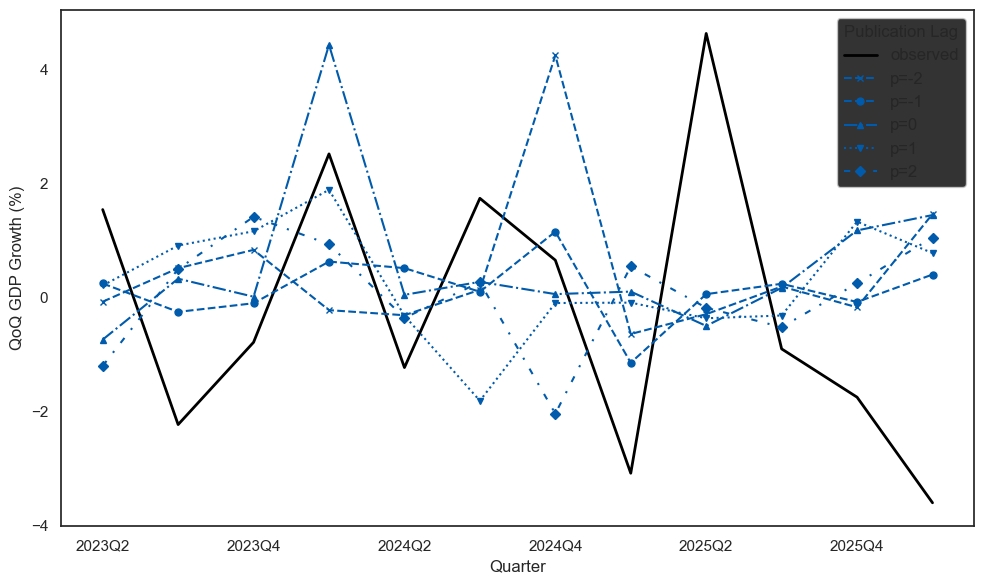

In [27]:
plot_df = df.rename(columns={
    'actuals': 'observed',
    'two_back': 'p=-2',
    'one_back': 'p=-1',
    'zero_back': 'p=0',
    'one_ahead': 'p=1',
    'two_ahead': 'p=2'
})
plot_df.index = pd.PeriodIndex(plot_df.index, freq='Q').astype(str)
fig, ax = plt.subplots(figsize=(10,6))

# Plot 'observed' as a black dashed line, no marker
plot_df['observed'].plot(
    ax=ax, color='black', linestyle='-', linewidth=2, label='observed'
)

# Define line styles and markers for other lines
line_styles = ['--', '--', '-.', ':', (0, (3, 5, 1, 5))]  # various dash styles
markers = ['x', 'o', '^', 'v', 'D']  # circle, square, triangle up/down, diamond

# Plot the rest with unique line styles and markers
for idx, col in enumerate(['p=-2', 'p=-1', 'p=0', 'p=1', 'p=2']):
    plot_df[col].plot(
        ax=ax,
        color=idb_blue,
        linestyle=line_styles[idx],
        marker=markers[idx],
        linewidth=1.5,
        markersize=5,
        label=col
    )

# Labels and grid
ax.set_title('')
ax.set_xlabel('Quarter', fontsize=12)
ax.set_ylabel('QoQ GDP Growth (%)', fontsize=12)
ax.legend(title='Publication Lag', fontsize=12, title_fontsize=12)
plt.tight_layout()

plt.show()

## Weighted Nowcast with Confidence Intervals

In [28]:
df = results_table[['actuals']].groupby('date').mean()
df

,actuals
date,
2023-06-01,1.543951
2023-09-01,-2.226164
2023-12-01,-0.783313
2024-03-01,2.520533
2024-06-01,-1.226503
2024-09-01,1.741308
2024-12-01,0.656454
2025-03-01,-3.079058
2025-06-01,4.631900


**Compute weighted average nowcasts and 95% confidence intervals for all horizons.** For each horizon we calculate the weighted mean, its standard error (SE), and the interval mean +/- 1.96 x SE.

In [29]:
lags = {
    -2: 'two_back',
    -1: 'one_back',
     0: 'zero_back',
     1: 'one_ahead',
     2: 'two_ahead'
}

for V, N in lags.items():
    # Read and prepare results_table fresh in each loop
    New_Table = filtered.copy()
    d = New_Table.loc[New_Table['Vintage'] == V]

    g = d.groupby('date')

    meanN = (
        (d['value'] * d['weight']).groupby(d['date']).sum()
        / g['weight'].sum()
    ).rename(N)

    seN = (1 / np.sqrt(g['weight'].sum())).rename(f'se_{N}')

    weighted = pd.concat([meanN, seN], axis=1)

    # Compute 95% confidence interval bounds
    weighted[f'ci_lower_{N}'] = weighted[N] - 1.96 * weighted[f'se_{N}']
    weighted[f'ci_upper_{N}'] = weighted[N] + 1.96 * weighted[f'se_{N}']

    # Concatenate the new columns to the main df
    df = df.join(weighted[[N, f'se_{N}', f'ci_lower_{N}', f'ci_upper_{N}']])

df.index = pd.PeriodIndex(df.index, freq='Q').astype(str)
df

,actuals,two_back,se_two_back,ci_lower_two_back,ci_upper_two_back,one_back,se_one_back,ci_lower_one_back,ci_upper_one_back,zero_back,...,ci_lower_zero_back,ci_upper_zero_back,one_ahead,se_one_ahead,ci_lower_one_ahead,ci_upper_one_ahead,two_ahead,se_two_ahead,ci_lower_two_ahead,ci_upper_two_ahead
date,,,,,,,,,,,,,,,,,,,,,
2023Q2,1.543951,-0.071633,0.427841,-0.910202,0.766936,0.247650,0.450216,-0.634774,1.130073,-0.736570,...,-1.610537,0.137398,0.212583,0.412778,-0.596461,1.021628,-1.197574,0.465975,-2.110885,-0.284263
2023Q3,-2.226164,0.515931,0.427841,-0.322638,1.354500,-0.250091,0.450216,-1.132515,0.632332,0.331534,...,-0.542434,1.205502,0.912897,0.412778,0.103852,1.721942,0.501336,0.465975,-0.411975,1.414647
2023Q4,-0.783313,0.837272,0.427841,-0.001297,1.675841,-0.099121,0.450216,-0.981544,0.783302,0.015915,...,-0.858053,0.889883,1.163675,0.412778,0.354630,1.972720,1.416870,0.465975,0.503559,2.330181
2024Q1,2.520533,-0.219922,0.427841,-1.058491,0.618647,0.631995,0.450216,-0.250428,1.514419,4.431736,...,3.557769,5.305704,1.890595,0.412778,1.081550,2.699640,0.936070,0.465975,0.022759,1.849381
2024Q2,-1.226503,-0.308863,0.427841,-1.147432,0.529706,0.517317,0.450216,-0.365107,1.399740,0.048545,...,-0.825423,0.922512,-0.316460,0.412778,-1.125505,0.492585,-0.356389,0.465975,-1.269700,0.556922
2024Q3,1.741308,0.136705,0.427841,-0.701864,0.975274,0.102277,0.450216,-0.780146,0.984700,0.276546,...,-0.597422,1.150514,-1.808734,0.412778,-2.617779,-0.999689,0.269001,0.465975,-0.644310,1.182312
2024Q4,0.656454,4.246585,0.427841,3.408016,5.085154,1.156316,0.450216,0.273892,2.038739,0.061505,...,-0.812463,0.935473,-0.095019,0.412778,-0.904064,0.714026,-2.034794,0.465975,-2.948105,-1.121483
2025Q1,-3.079058,-0.638388,0.427841,-1.476956,0.200181,-1.142496,0.450216,-2.024920,-0.260073,0.105584,...,-0.768384,0.979552,-0.087954,0.412778,-0.896999,0.721091,0.547821,0.465975,-0.365490,1.461133
2025Q2,4.631900,-0.290549,0.427841,-1.129118,0.548019,0.060699,0.450216,-0.821724,0.943122,-0.496414,...,-1.370382,0.377553,-0.362216,0.412778,-1.171261,0.446829,-0.177438,0.465975,-1.090749,0.735874


**Plot the weighted nowcast with confidence bands, one panel per horizon.** The shaded area shows the 95% interval around the weighted average, illustrating how uncertainty changes across forecasting horizons.

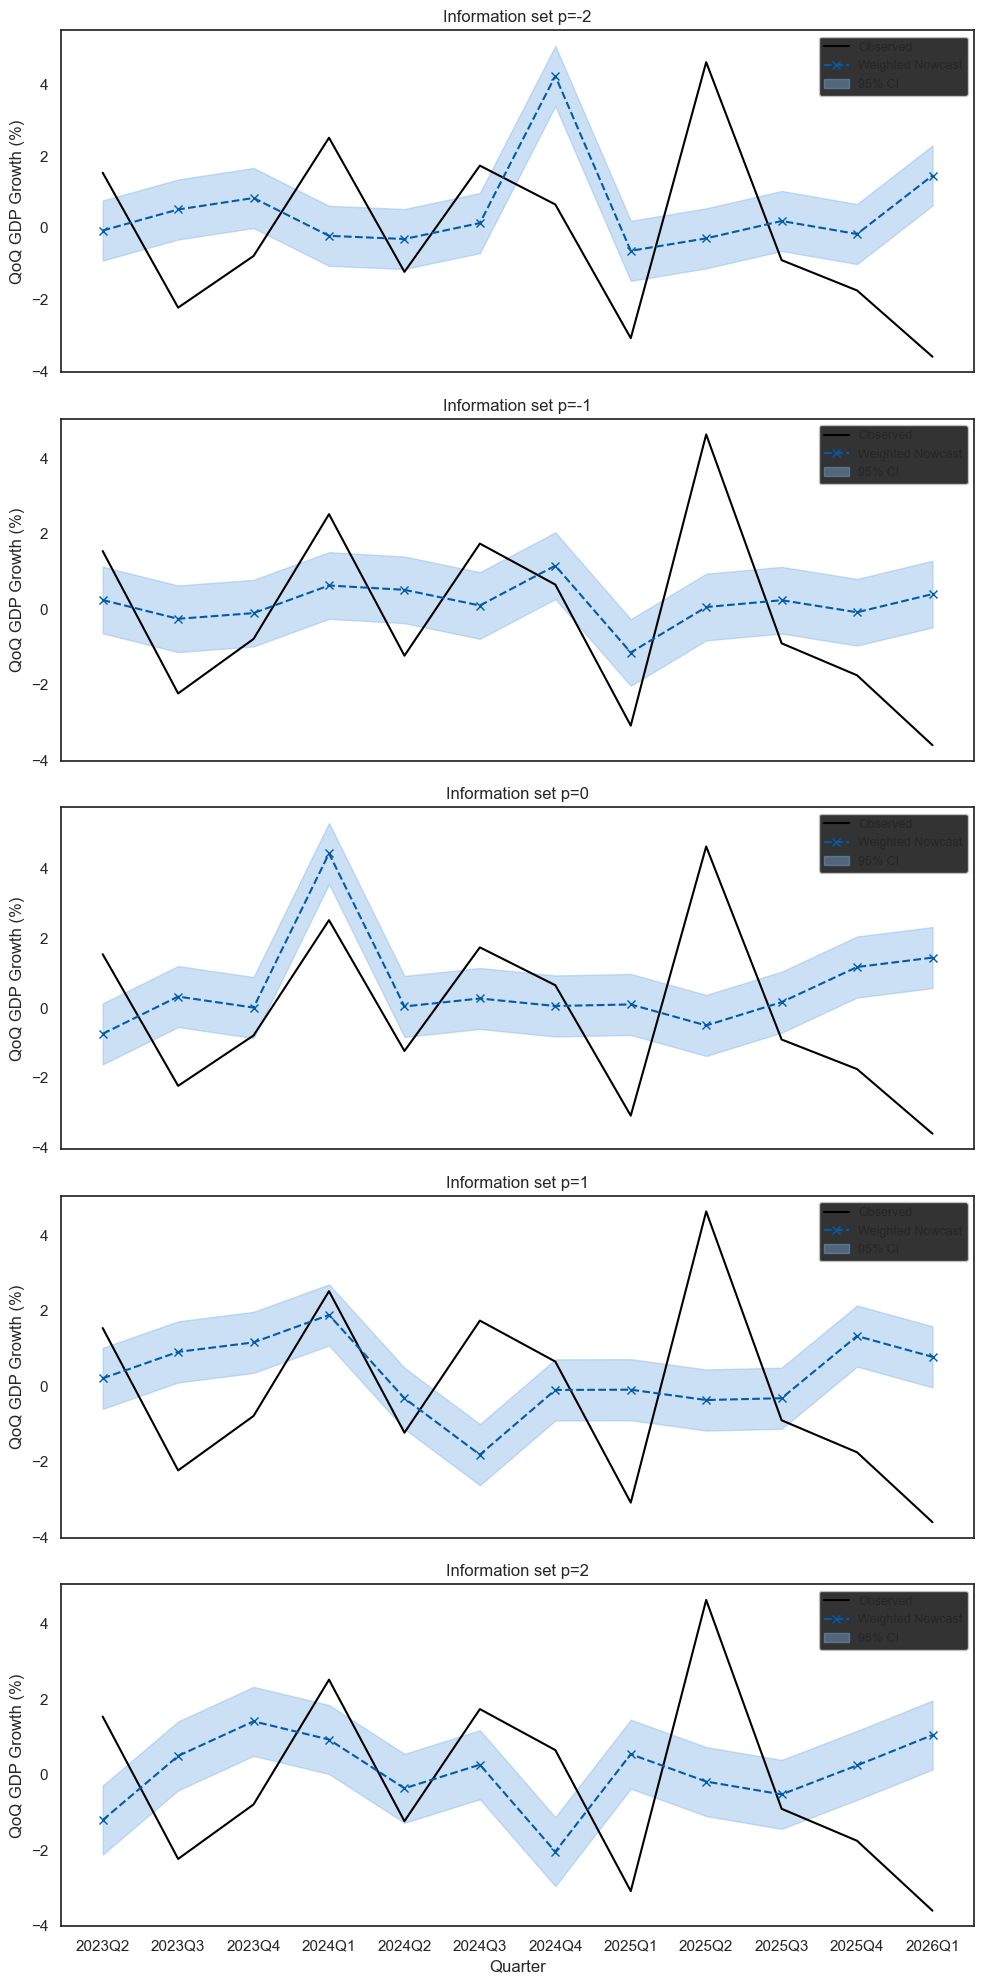

In [30]:
lags = {
    -2: 'two_back',
    -1: 'one_back',
     0: 'zero_back',
     1: 'one_ahead',
     2: 'two_ahead'
}

fig, axes = plt.subplots(nrows=5, ncols=1, figsize=(10, 20), sharex=True)

# ------------------------------------------------
# Loop over each vintage and plot
for ax, (V, N) in zip(axes, lags.items()):
    # Plot actuals
    ax.plot(df.index, df['actuals'], color='black', linestyle='-', label='Observed')
    
    # Plot nowcast for vintage N
    ax.plot(df.index, df[N], color=idb_blue, linestyle='--', marker='x', label=f'Weighted Nowcast')
    
    # Plot confidence interval as a shaded area
    ax.fill_between(
        df.index,
        df[f'ci_lower_{N}'],
        df[f'ci_upper_{N}'],
        color=idb_light_blue,
        alpha=0.4,
        label='95% CI'
    )
    
    # Titles and labels
    ax.set_title(f'Information set p={V}', fontsize=12)
    ax.set_ylabel('QoQ GDP Growth (%)')
    ax.legend(fontsize=9, loc='upper right')

axes[-1].set_xlabel('Quarter')

plt.tight_layout()
plt.show()

# Out of sample

In [31]:
import os
import pandas as pd
import numpy as np
# date_str / PATH_* already come from the config loader at the top of the
# notebook; re-derived here so this section still runs on its own.
date_str    = cfg.DATE_STR
PATH_OUTPUT = os.path.join(P["output"], date_str)
PATH_DATA   = P["data"]


import matplotlib.ticker as ticker
import matplotlib.pyplot as plt
import seaborn as sns
'''
# Define the color scheme
idb_blue = "#005BAC"
idb_light_blue = "#7FB3E6"

# Load results
forecast_file = f"{date_str} 3_nwcst Tab fcst.xlsx"
performance_file = f"{date_str} 3_nwcst Tab perf.xlsx"
outofsample_file = f"{date_str} 3_nwcst Tab oos.xlsx"


results_table = pd.read_excel(f"{PATH_OUTPUT}/{forecast_file}", index_col='date', parse_dates=True)
results_table.index = pd.to_datetime(results_table.index, format="%Y-%m-%d")
performance_table = pd.read_excel(f"{PATH_OUTPUT}/{performance_file}", parse_dates=True)
'''

forecast = filtered.copy()
forecast = forecast.dropna(how='all', axis=0)

performance = performance_table.copy()
performance = performance.dropna(how='any', axis=0)
performance['inv_rmse'] = 1 / (performance['RMSE']** 2)
performance['weight'] = performance.groupby('Vintage')['inv_rmse'].transform(lambda x: x / x.sum())

performance.reset_index(drop=False, inplace=True)


performance = performance[['Vintage', 'estimator', 'spec', 'weight']]
performance = performance.set_index('Vintage')
performance.index = performance.index.astype(str).str.replace("-2",'two_back')
performance.index = performance.index.astype(str).str.replace("-1",'one_back')
performance.index = performance.index.astype(str).str.replace("0",'zero_back')
performance.index = performance.index.astype(str).str.replace("1",'one_ahead')
performance.index = performance.index.astype(str).str.replace("2",'two_ahead')
performance = performance.reset_index()

performance.rename(columns={'Vintage': 'horizon'}, inplace=True)

#forecast = forecast.reset_index().melt(id_vars=['date', 'actuals', 'estimator', 'spec'],
#        value_vars=['two_back', 'one_back', 'zero_back', 'one_ahead', 'two_ahead'],
#        var_name='Vintage',
#        value_name='value')
forecast = forecast.drop(columns=['weight'], errors='ignore')
forecast = forecast.merge(performance, on=['horizon', 'estimator', 'spec'])
forecast = forecast.dropna(how='all', axis=0)
forecast = forecast[~forecast['value'].isna()]
forecast['value'] = ( ((1+ ( forecast['value']/100) )**4)-1 )*100
performance

,horizon,estimator,spec,weight
0,two_back,OLS,bench5p3,0.000007
1,one_back,OLS,bench5p3,0.070722
2,zero_back,OLS,bench5p3,0.000522
3,one_ahead,OLS,bench5p3,0.000006
4,two_ahead,OLS,bench5p3,0.070848
...,...,...,...,...
100,two_back,GBT,lars67p3,0.069233
101,one_back,GBT,lars67p3,0.037845
102,zero_back,GBT,lars67p3,0.070431
103,one_ahead,GBT,lars67p3,0.059991


**Build the out-of-sample summary statistics.** Load observed GDP growth, then compute the simple average, GBT-only, and RMSE-weighted nowcast for the most recent (out-of-sample) period.

In [32]:
data = pd.read_csv(f"{PATH_DATA}/data.csv", parse_dates=["date"], index_col='date')
data = data[['RGDP0000']].dropna()

from statsmodels.tsa.seasonal import seasonal_decompose
data['RGDP0000'] = seasonal_decompose(data['RGDP0000'].dropna(how='all', axis=0), model='additive', extrapolate_trend='freq', period=4).trend

'''
data = pd.read_csv(f"{PATH_FORMAT}/data_full.csv", parse_dates=["date"], index_col='date')['RGDP0000'].dropna()
'''
gdp = data.resample('Q').agg({'RGDP0000': 'mean'})
gdp.index = gdp.index.to_period('Q').asfreq('M').to_timestamp()
gdp = (gdp.pct_change(periods=1)).dropna()*100
gdp.rename(columns = { 'RGDP0000' : 'actuals' } , inplace=True)
gdp['actuals'] = (((1+gdp['actuals']/100)**4) - 1)*100

actuals = pd.DataFrame(gdp['actuals'].groupby(gdp.index).mean())

avg = pd.DataFrame(forecast.groupby('date')['value'].mean()).rename(columns = {'value' : 'avg'})

est_fcst = pd.DataFrame( forecast.groupby(['date', 'estimator'])['value'].mean() ).rename(columns = {'value' : 'avg'}).reset_index()
gbt_fcst = est_fcst[est_fcst['estimator']=='GBT'].set_index('date')[['avg']].rename(columns = {'avg' : 'GBT'})

avg = pd.concat([avg, gbt_fcst], axis=1)

wavg = forecast.groupby('date').apply(lambda g: np.average(g['value'], weights=g['weight']) if g['weight'].sum() > 0 else np.nan).reset_index(name='weighted_avg').set_index('date')

avg = pd.concat([avg, wavg], axis=1)
avg.index = pd.to_datetime(avg.index)
avg

C:\Users\guerr\AppData\Local\Temp\ipykernel_12548\1029502603.py:10: FutureWarning: 'Q' is deprecated and will be removed in a future version, please use 'QE' instead.
  gdp = data.resample('Q').agg({'RGDP0000': 'mean'})
C:\Users\guerr\AppData\Local\Temp\ipykernel_12548\1029502603.py:25: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  wavg = forecast.groupby('date').apply(lambda g: np.average(g['value'], weights=g['weight']) if g['weight'].sum() > 0 else np.nan).reset_index(name='weighted_avg').set_index('date')


,avg,GBT,weighted_avg
date,,,
2023-06-01,-1.112294,-1.456701,-1.226614
2023-09-01,2.006862,1.711731,1.698248
2023-12-01,3.576203,2.531180,2.685243
2024-03-01,10.003623,0.124047,5.875967
2024-06-01,-0.239884,-0.278896,-0.535071
2024-09-01,-0.775012,-0.279921,-0.832598
2024-12-01,3.985159,1.690668,3.228039
2025-03-01,-1.044370,-0.297358,-0.327016
2025-06-01,-0.911064,-2.416936,-0.842167


**Load the out-of-sample prediction panel and filter it by quality.** We read all model predictions for the nowcast horizon, convert to annualized growth rates, and keep only models that pass the same RMSE threshold used in-sample.

In [33]:
out_of_sample = pd.read_excel(f"{PATH_OUTPUT}/{outofsample_file}", parse_dates=True)
out_of_sample['date'] = pd.to_datetime(out_of_sample['date'])
out_of_sample['nowcast'] = (((1+out_of_sample['nowcast']/100)**4) - 1)*100


# Filter out of sample by RMSE
filtered_grouped = (
    filtered[filtered['Vintage'] == 2]
    .groupby(['spec', 'estimator'], as_index=False)
    .agg({
        'RMSE': 'mean',
        #'threshold': 'mean'
    })
)

out_of_sample = out_of_sample.merge(
    filtered_grouped,
    on=['spec', 'estimator'],
    how='left'
)
out_of_sample.dropna(subset=['RMSE'], inplace=True)
#out_of_sample = out_of_sample[out_of_sample['RMSE'] <= out_of_sample['threshold']]
out_of_sample

,date,nowcast,estimator,spec,RMSE
0,2026-06-01,2.573745,OLS,bench5p3,3.054418
1,2026-09-01,3.983712,OLS,bench5p3,3.054418
2,2026-06-01,-0.124284,OLSR,bench5p3,2.570684
3,2026-09-01,-0.172813,OLSR,bench5p3,2.570684
4,2026-06-01,0.998847,ENET,bench5p3,3.003257
5,2026-09-01,0.992541,ENET,bench5p3,3.003257
6,2026-06-01,0.999216,LASSO,bench5p3,3.003125
7,2026-09-01,0.993346,LASSO,bench5p3,3.003125
8,2026-06-01,7.149283,DT,bench5p3,3.463564
9,2026-09-01,19.855082,DT,bench5p3,3.463564


**Compute the weighted average and confidence interval for the out-of-sample nowcast.** Models are weighted by their historical RMSE, and a 5-95 percentile band is calculated across model predictions.

In [34]:

#lower_bound = out_of_sample['nowcast'].quantile(0.10)
#upper_bound = out_of_sample['nowcast'].quantile(0.90)
#out_of_sample['nowcast'] = out_of_sample['nowcast'].where((out_of_sample['nowcast'] >= lower_bound) & (out_of_sample['nowcast'] <= upper_bound), np.nan)
'''
quantiles = out_of_sample.groupby('date')['nowcast'].quantile([0.10, 0.90]).unstack()
out_of_sample = out_of_sample.merge(quantiles, on='date', suffixes=('', '_quantile'))
out_of_sample['nowcast'] = out_of_sample['nowcast'].where(
    (out_of_sample['nowcast'] >= out_of_sample[0.10]) & 
    (out_of_sample['nowcast'] <= out_of_sample[0.90]), 
    np.nan
)
out_of_sample = out_of_sample.drop(columns=[0.10, 0.90])
'''

out_of_sample = out_of_sample.merge(pd.DataFrame(performance.groupby(['estimator', 'spec'])['weight'].mean()).reset_index(), on=['estimator', 'spec']).set_index('date')

oos_avg = pd.DataFrame(out_of_sample.groupby(out_of_sample.index)['nowcast'].mean()).rename(columns = {'nowcast' : 'avg'})

oos_gbt = pd.DataFrame(out_of_sample.groupby(['date', 'estimator'])['nowcast'].mean().reset_index()).set_index('date').rename(columns = {'nowcast' : 'GBT'})
oos_gbt = pd.DataFrame(oos_gbt[oos_gbt['estimator'] == 'GBT']['GBT'])
oos_avg = pd.concat([oos_avg, oos_gbt], axis=1)

out_of_sample = out_of_sample.dropna(how='any', axis=0)
wavg = out_of_sample.groupby(out_of_sample.index).apply(lambda g: np.average(g['nowcast'], weights=g['weight']) if g['weight'].sum() > 0 else np.nan).reset_index(name='weighted_avg').set_index('date')
oos_avg = pd.concat([oos_avg, wavg], axis=1)

out_of_sample = out_of_sample.dropna(how='any', axis=0)
dfrange = out_of_sample.groupby(out_of_sample.index)['nowcast'].agg(min='min', max='max').reset_index().set_index('date')
df_ci = (
    out_of_sample
    .groupby(out_of_sample.index)['nowcast']
    .quantile([0.05, 0.95])
    .unstack()
    .rename(columns={0.05: 'ci_lower', 0.95: 'ci_upper'})
)
oos_avg = pd.concat([oos_avg, dfrange, df_ci], axis=1)

oos_avg.index = pd.to_datetime(oos_avg.index)
oos_avg

,avg,GBT,weighted_avg,min,max,ci_lower,ci_upper
date,,,,,,,
2026-06-01,3.643439,3.806862,3.488717,-4.690865,16.239444,-3.907836,10.636247
2026-09-01,4.730337,4.550819,4.572013,-0.172813,19.855082,-0.081517,16.020301


**Combine in-sample and out-of-sample nowcast summaries** into a single table, merging columns with the same name.

In [35]:
data = pd.concat( [ avg , oos_avg ] , axis=1 )
data = data.groupby(level=0, axis=1).sum(min_count=1)
data

C:\Users\guerr\AppData\Local\Temp\ipykernel_12548\718950512.py:2: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  data = data.groupby(level=0, axis=1).sum(min_count=1)


,GBT,avg,ci_lower,ci_upper,max,min,weighted_avg
date,,,,,,,
2023-06-01,-1.456701,-1.112294,NaN,NaN,NaN,NaN,-1.226614
2023-09-01,1.711731,2.006862,NaN,NaN,NaN,NaN,1.698248
2023-12-01,2.531180,3.576203,NaN,NaN,NaN,NaN,2.685243
2024-03-01,0.124047,10.003623,NaN,NaN,NaN,NaN,5.875967
2024-06-01,-0.278896,-0.239884,NaN,NaN,NaN,NaN,-0.535071
2024-09-01,-0.279921,-0.775012,NaN,NaN,NaN,NaN,-0.832598
2024-12-01,1.690668,3.985159,NaN,NaN,NaN,NaN,3.228039
2025-03-01,-0.297358,-1.044370,NaN,NaN,NaN,NaN,-0.327016
2025-06-01,-2.416936,-0.911064,NaN,NaN,NaN,NaN,-0.842167


**Add the observed GDP growth series to the combined table**, so we can compare nowcasts against actual outcomes side by side.

In [36]:
data = pd.concat([ data, actuals ] , axis=1)
data = pd.concat([ data, gdp ] , axis=1)
data

,GBT,avg,ci_lower,ci_upper,max,min,weighted_avg,actuals,actuals
date,,,,,,,,,
2012-06-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.731086,2.731086
2012-09-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.803425,3.803425
2012-12-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.866327,0.866327
2013-03-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.728307,1.728307
2013-06-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.795297,5.795297
2013-09-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.474858,6.474858
2013-12-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.107406,4.107406
2014-03-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.373084,5.373084
2014-06-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.261122,4.261122


**Draw the final nowcast chart.** Shows observed GDP growth (black), the simple average nowcast (red dotted), and the RMSE-weighted nowcast (indigo dashed) with a grey uncertainty band. Sample is restricted to 2022 onwards.

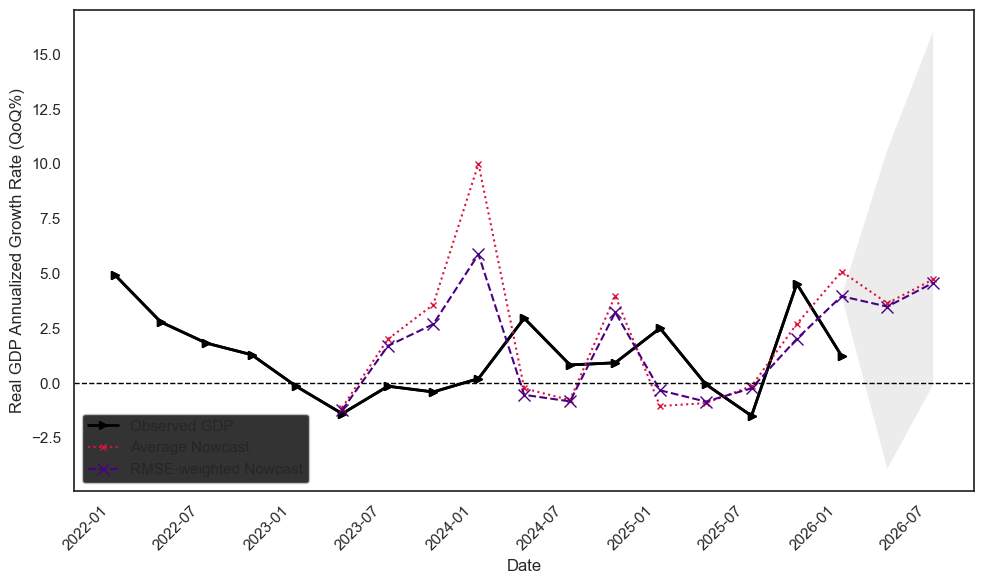

In [37]:
import matplotlib.pyplot as plt

dataframe = data.copy()

# Ensure the last observed point has no interval
last_valid_idx = dataframe['actuals'].last_valid_index()
dataframe.at[last_valid_idx, 'ci_lower'] = dataframe.at[last_valid_idx, 'weighted_avg']
dataframe.at[last_valid_idx, 'ci_upper'] = dataframe.at[last_valid_idx, 'weighted_avg']

# Restrict sample
dataframe = dataframe[dataframe.index > "2022-01-01"]

plt.figure(figsize=(10, 6))

# Confidence interval band
plt.fill_between(
    dataframe.index,
    dataframe['ci_lower'],
    dataframe['ci_upper'],
    color='grey',
    alpha=0.15,
    edgecolor='none',
    label="_nolegend_"
)

# Observed GDP
plt.plot(
    dataframe.index,
    dataframe['actuals'],
    color='black',
    marker='>',
    linewidth=2,
    label='Observed GDP'
)

# Average nowcast
plt.plot(
    dataframe.index,
    dataframe['avg'],
    color='crimson',
    linestyle=":",
    marker='x',
    markersize=5,
    label='Average Nowcast'
)

# Weighted nowcast
plt.plot(
    dataframe.index,
    dataframe['weighted_avg'],
    color='indigo',
    linestyle="--",
    marker='x',
    markersize=8,
    label='RMSE-weighted Nowcast'
)

# Zero line
plt.axhline(y=0, color='black', linestyle='--', linewidth=1)

# Labels
plt.xlabel('Date', fontsize=12)
plt.ylabel('Real GDP Annualized Growth Rate (QoQ%)', fontsize=12)

# Rotate x labels
plt.xticks(rotation=45)

# Remove duplicate legend entries (safety)
handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plt.legend(by_label.values(), by_label.keys(), loc='lower left')

# Layout and save
plt.tight_layout()
plt.savefig(f"{PATH_OUTPUT}/{date_str} 4_rslt Fig out_of_sample.png",
            dpi=300,
            bbox_inches='tight')

plt.show()